In [2]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd

In [3]:
# Linear Regression
# steps to be followed

#data import
#data cleaning-->null,replace
#Sampling-->train_test_splite
#Linreg
#Build Model-->fit
#linreg.score-->Rsquare
#AdjRsquare
#linreg.intercept_
#linreg.coef_
#pred-->train_x,test_x
#err_train
#err_mean()
#hist plot
#skew()
#kurt+3
#scatter plot
#data fram-->x=Actual y=pred
#regplot
#err_test
#mse
#rmse
#mape
#acc
# To be taken as note
# 1) data should be numeric and continuous only
# 2) hist should be normaly distributed
# 3) Data should be equaly scattered
# 4) in regplot all data should be linear pred line


In [4]:
import pandas as pd

In [5]:
# LungCapData

In [6]:
pd.read_csv(r"C:\Users\user\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\F81493623DA4A6C582DE384F23169A366E91AA5E\transfers\2026-37\LungCapData.csv")

,LungCap,Age,Height,Smoke,Gender,Caesarean
0,6.475,6,62.1,no,male,no
1,10.125,18,74.7,yes,female,no
2,9.550,16,69.7,no,female,yes
3,11.125,14,71.0,no,male,no
4,4.800,5,56.9,no,male,no
...,...,...,...,...,...,...
720,5.725,9,56.0,no,female,no
721,9.050,18,72.0,yes,male,yes
722,3.850,11,60.5,yes,female,no
723,9.825,15,64.9,no,female,no


In [7]:
lung=pd.read_csv(r"C:\Users\user\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\F81493623DA4A6C582DE384F23169A366E91AA5E\transfers\2026-37\LungCapData.csv")

In [8]:
lung.isnull().sum()[lung.isnull().sum()>0]

Series([], dtype: int64)

In [9]:
lung.shape

(725, 6)

In [10]:
lung.Smoke.replace({'no':0,'yes':1},inplace=True)
lung.Gender.replace({'male':1,'female':0},inplace=True)
lung.Caesarean.replace({'no':0,'yes':1},inplace=True)

In [11]:
lung.head()

,LungCap,Age,Height,Smoke,Gender,Caesarean
0,6.475,6,62.1,0,1,0
1,10.125,18,74.7,1,0,0
2,9.550,16,69.7,0,0,1
3,11.125,14,71.0,0,1,0
4,4.800,5,56.9,0,1,0


In [12]:
from sklearn.model_selection import train_test_split
lung_train,lung_test=train_test_split(lung,test_size=.2)

In [13]:
lung_train_x=lung_train.iloc[::,1:]
lung_train_y=lung_train.iloc[::,0]

In [14]:
lung_test_x=lung_test.iloc[::,1:]
lung_test_y=lung_test.iloc[::,0]

In [15]:
lung_test_x

,Age,Height,Smoke,Gender,Caesarean
230,11,65.1,0,1,0
654,12,65.8,0,1,1
113,3,55.9,0,1,0
157,5,55.8,0,0,1
680,13,68.4,0,1,0
...,...,...,...,...,...
631,10,66.5,0,0,0
96,16,71.1,1,1,0
81,16,69.3,0,1,0
723,15,64.9,0,0,0


In [16]:
from sklearn.linear_model import LinearRegression
linreg=LinearRegression()

In [17]:
linreg.fit(lung_train_x,lung_train_y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
linreg.score(lung_train_x,lung_train_y)

0.8574877488048279

In [19]:
lung_train_x.shape[0]

580

In [20]:
lung_train_x.shape[1]

5

In [21]:
lung_train_x.shape

(580, 5)

In [22]:
Rsquare=linreg.score(lung_train_x,lung_train_y)
n=lung_train_x.shape[0]
k=lung_train_x.shape[1]
adjrsquare=1-(1-Rsquare)*(n-1)/(n-k-1)
adjrsquare

0.8562463528884936

In [23]:
print(linreg.intercept_)

-11.016158040455904


In [24]:
linreg.coef_

array([ 0.16972526,  0.2569227 , -0.48432606,  0.3916156 , -0.23752758])

In [25]:
pred_train=linreg.predict(lung_train_x)
pred_test=linreg.predict(lung_test_x)


In [26]:
err_train=lung_train_y-pred_train

In [27]:
err_train

531    0.676710
151   -0.392313
490   -0.241788
445    1.769475
566    0.260096
         ...   
365   -0.992576
74    -0.818093
160    0.638184
197   -0.111806
382    1.106706
Name: LungCap, Length: 580, dtype: float64

In [28]:
err_train.mean()

np.float64(4.0366177833267764e-15)

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns


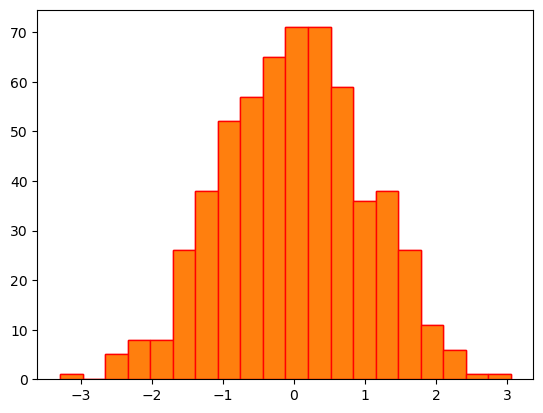

In [30]:
plt.hist(err_train,edgecolor='red',bins=20);plt.hist(err_train,edgecolor='red',bins=20);

In [31]:
err_train.skew()

np.float64(-0.0485245528836537)

In [32]:
err_train.kurtosis()+3

np.float64(2.78095452036759)

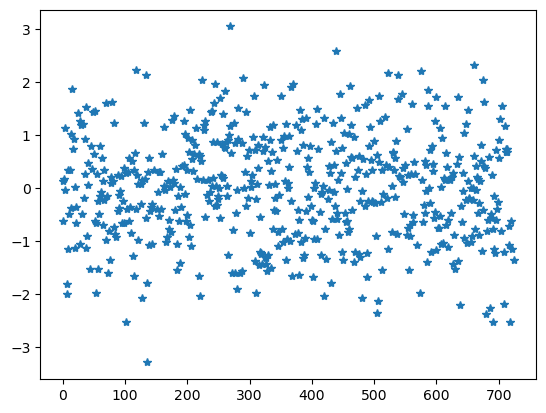

In [33]:
plt.plot(err_train,'*')

In [34]:
pred_act=pd.DataFrame()
pred_act['Actual']=lung_train_y
pred_act['Pred']=pred_train
pred_act

,Actual,Pred
531,8.500,7.823290
151,6.450,6.842313
490,4.250,4.491788
445,6.150,4.380525
566,8.700,8.439904
...,...,...
365,6.225,7.217576
74,6.250,7.068093
160,9.725,9.086816
197,7.850,7.961806


<Axes: xlabel='Actual', ylabel='Pred'>

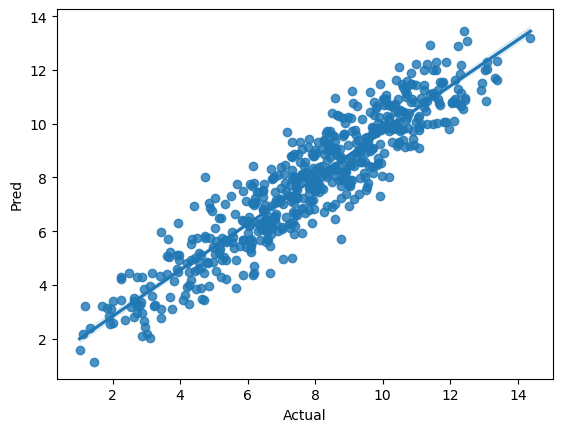

In [35]:
sns.regplot(x='Actual',y='Pred',data=pred_act)

In [36]:
err_test=lung_test_y-pred_test
err_test

230   -0.043103
654    0.819853
113    1.628388
157    1.618773
680    0.869601
         ...   
631    1.008546
96    -2.323940
81     2.004195
723    1.620996
483    0.443367
Name: LungCap, Length: 145, dtype: float64

In [37]:
import numpy as np

In [38]:
mse=np.mean(np.square(err_test))
mse

np.float64(1.1457143297512398)

In [39]:
np.sqrt(mse)

np.float64(1.0703804602809412)

In [40]:
mape=np.mean(np.abs(err_test*100/lung_test_y))

In [41]:
mape

np.float64(15.385697185779833)

In [42]:
acc=100-mape
print(acc)

84.61430281422017


In [43]:
!pip install streamlit

In [44]:
# model saved

In [45]:
import pickle

# 'linreg' is the exact name of your trained model from your screenshot
with open('lung_cap_model.pkl', 'wb') as file:
    pickle.dump(linreg, file)

print("Success! Your model has been saved as 'lung_cap_model")

Success! Your model has been saved as 'lung_cap_model
